# Why does keeping the last reasoning work in the cooking games and not in Connect Four?

`lr4` thinks about every fourth turn and keeps only its last reasoning in the context, to read on the turns in between
(`er4` erases it, `r4` keeps them all, `e1` thinks every turn and keeps none). In the cooking games `lr4` plays about as well as
`e1` for a fifth of the tokens; in Connect Four it plays like every other every-4 mode, far below `e1`.

This notebook reads the reasonings of both games to see why. It has four parts:

1. **The contrast**, on matched games, split into its three ingredients (how often it thinks; last vs none; last vs all).
2. **What a game gives the memory to work with**: how many reasonings there are, how many turns can read one, and how many reasonings are empty.
3. **What happens on the turns after a reasoning**, with the reasoning visible (`lr4`, `r4`) and erased (`er4`).
4. **A classification of 180 reasonings**: what a reasoning contains that could still be useful on the next turns, and whether it was.

Data: cooking games of Qwen3-1.7B, 4B and 8B (prompt CoT; the 4B games are those of Experiments 7, 7e and 8, read from their logs),
Connect Four of Qwen3-4B (plain and free prompts, the memory grids). `memory_analysis.py` has the parsers and the rubric.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, wilcoxon
from records import load_table
import memory_analysis as ma

RESULTS = "results"
pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 11, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
                     "axes.axisbelow": True})
# one colour per mode everywhere (checked for colour-blind separation); the values are written on the marks
COLOR = {"e1": "#2a78d6", "er4": "#eb6834", "lr4": "#1baf7a", "r4": "#eda100", "0": "#e87ba4"}
MODES = ["e1", "er4", "lr4", "r4"]
SHORT = {"Qwen/Qwen3-1.7B": "1.7B", "Qwen/Qwen3-4B": "4B", "Qwen/Qwen3-8B-FP8": "8B"}

games = load_table(RESULTS)
cook = games[(games.game == "cooking") & (games.prompt == "CoT") & games["mode"].isin(MODES + ["0"])].copy()
cook["level"] = cook.level.astype(str)
c4 = games[(games.game == "connect_four") & (games.source == "benchmark-duel") & games["mode"].isin(MODES)
           & games.level.str.startswith("self") & ~games.prompt.str.contains("+", regex=False)].copy()
c4["sc"] = c4.result.map({"win": 1, "draw": 0.5, "loss": 0})

turns = ma.cooking_turns(RESULTS); turns = turns[(turns.prompt == "CoT") & turns["mode"].isin(MODES)]
moves = ma.connect_four_turns(RESULTS); moves = moves[(moves.model == "Qwen/Qwen3-4B") & moves["mode"].isin(MODES)]
print(f"cooking: {len(cook)} games, {len(turns)} turns read from the logs; Connect Four: {len(c4)} games, {len(moves)} judged moves")

def fisher(a, b):
    a, b = a.dropna().astype(bool), b.dropna().astype(bool)
    return fisher_exact([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])[1]
def sem(s): return s.std(ddof=1) / np.sqrt(len(s))

cooking: 960 games, 55570 turns read from the logs; Connect Four: 639 games, 11773 judged moves


## 1. The contrast

Cooking games are compared on the levels and seeds that every mode played (a paired comparison, Wilcoxon test on the per-game differences).
The score of a cooking game is the share of the recipe's points; in Connect Four it is the win rate against the model itself.

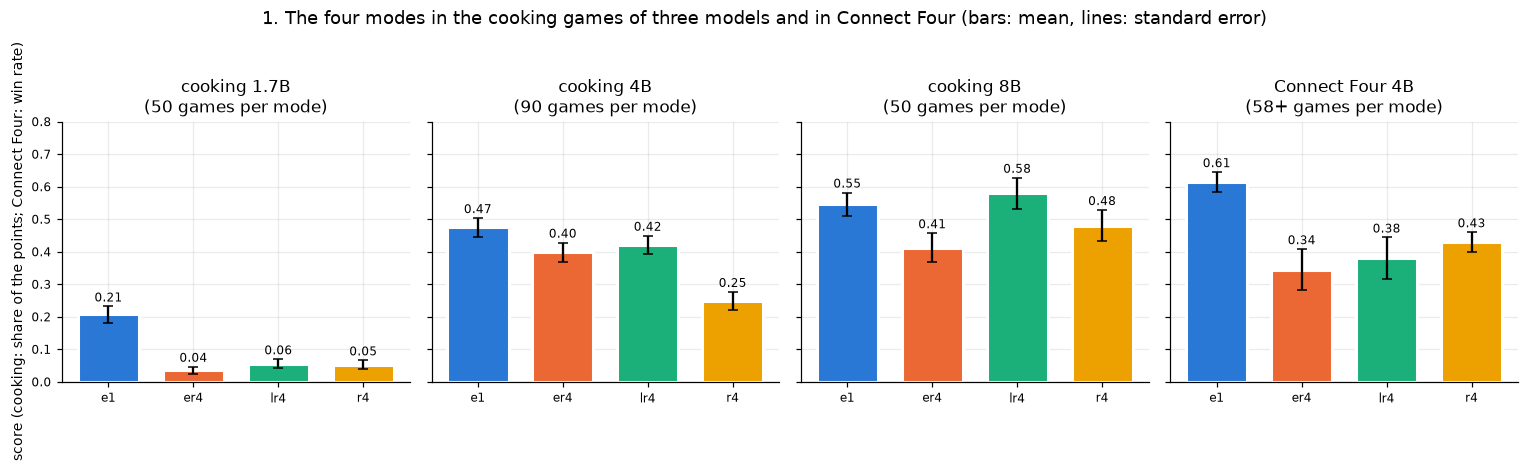

setting,cooking 1.7B,cooking 4B,cooking 8B,Connect Four 4B
effect,,,,
thinking less often (er4 - e1),-0.172,-0.076,-0.133,-0.270
keeping the last reasoning (lr4 - er4),0.021,0.022,0.167,0.034
keeping them all (r4 - lr4),-0.003,-0.172,-0.099,0.050


In [2]:
rows, tests = [], []
for model, d in cook.groupby("model"):
    p = d.pivot_table(index=["level", "seed"], columns="mode", values="norm_score")[[m for m in MODES if m in d["mode"].unique()]].dropna()
    for m in p: rows.append(dict(setting=f"cooking {SHORT[model]}", mode=m, score=p[m].mean(), se=sem(p[m]), games=len(p)))
    for a, b, what in [("er4", "e1", "thinking less often (er4 - e1)"), ("lr4", "er4", "keeping the last reasoning (lr4 - er4)"), ("r4", "lr4", "keeping them all (r4 - lr4)")]:
        diff = p[a] - p[b]
        tests.append(dict(setting=f"cooking {SHORT[model]}", effect=what, difference=diff.mean(), relative=diff.mean() / p[b].mean(), p=wilcoxon(diff[diff != 0]).pvalue, games=len(p)))
for m, d in c4.groupby("mode"): rows.append(dict(setting="Connect Four 4B", mode=m, score=d.sc.mean(), se=sem(d.sc), games=len(d)))
for a, b, what in [("er4", "e1", "thinking less often (er4 - e1)"), ("lr4", "er4", "keeping the last reasoning (lr4 - er4)"), ("r4", "lr4", "keeping them all (r4 - lr4)")]:
    x, y = c4[c4["mode"] == a], c4[c4["mode"] == b]
    tests.append(dict(setting="Connect Four 4B", effect=what, difference=x.sc.mean() - y.sc.mean(), relative=(x.sc.mean() - y.sc.mean()) / y.sc.mean(), p=fisher(x.sc == 1, y.sc == 1), games=f"{len(x)} vs {len(y)}"))
score = pd.DataFrame(rows); effects = pd.DataFrame(tests)

settings = ["cooking 1.7B", "cooking 4B", "cooking 8B", "Connect Four 4B"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, s in zip(axes, settings):
    d = score[score.setting == s].set_index("mode").loc[MODES]
    ax.bar(range(4), d.score, yerr=d.se, capsize=3, color=[COLOR[m] for m in MODES], width=0.72, edgecolor="white", linewidth=2)
    for i, (v, e) in enumerate(zip(d.score, d.se)): ax.text(i, v + e + 0.015, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_xticks(range(4)); ax.set_xticklabels(MODES); ax.set_title(f"{s}\n({d.games.iloc[0] if s.startswith('cooking') else int(d.games.min())}{'' if s.startswith('cooking') else '+'} games per mode)"); ax.set_ylim(0, 0.8)
axes[0].set_ylabel("score (cooking: share of the points; Connect Four: win rate)")
fig.suptitle("1. The four modes in the cooking games of three models and in Connect Four (bars: mean, lines: standard error)", y=1.04)
plt.tight_layout(); plt.show()
effects.pivot(index="effect", columns="setting", values="difference").loc[["thinking less often (er4 - e1)", "keeping the last reasoning (lr4 - er4)", "keeping them all (r4 - lr4)"], settings].round(3)

In [3]:
effects.assign(p=effects.p.round(3), difference=effects.difference.round(3), relative=(effects.relative * 100).round(0).astype(int).astype(str) + "%")[["setting", "effect", "difference", "relative", "p", "games"]]

,setting,effect,difference,relative,p,games
0,cooking 1.7B,thinking less often (er4 - e1),-0.172,-83%,0.000,50
1,cooking 1.7B,keeping the last reasoning (lr4 - er4),0.021,59%,0.198,50
2,cooking 1.7B,keeping them all (r4 - lr4),-0.003,-5%,0.736,50
3,cooking 4B,thinking less often (er4 - e1),-0.076,-16%,0.008,90
4,cooking 4B,keeping the last reasoning (lr4 - er4),0.022,6%,0.283,90
5,cooking 4B,keeping them all (r4 - lr4),-0.172,-41%,0.000,90
6,cooking 8B,thinking less often (er4 - e1),-0.133,-24%,0.011,50
7,cooking 8B,keeping the last reasoning (lr4 - er4),0.167,40%,0.008,50
8,cooking 8B,keeping them all (r4 - lr4),-0.099,-17%,0.111,50
9,Connect Four 4B,thinking less often (er4 - e1),-0.270,-44%,0.000,58 vs 262


**Reading 1.** The contrast between the two games is real, but it is not one effect and it is not the same in every model.

- **Thinking less often costs more in Connect Four.** Going from every turn to every fourth (no memory in both: `er4` against `e1`) loses
  16% of the score in cooking with the 4B model and 24% with the 8B, and 44% in Connect Four. This is most of the gap.
- **Keeping the last reasoning helps only the 8B model.** `lr4` against `er4`: +0.17 in cooking with the 8B (p = 0.008), +0.02 with the 4B
  (not distinguishable), +0.03 in Connect Four with the 4B (not distinguishable). So on the model Connect Four was played with, the last
  reasoning adds nothing measurable in either game.
- **Keeping all the reasonings hurts the 4B model in cooking** (`r4` loses 0.17 to `lr4`, p < 0.001) and not in Connect Four. With the 4B,
  `lr4` looks good in cooking mainly because `r4` is bad.
- The 1.7B model only plays when it thinks every turn; part 2 shows why.

The two games were not played with the same models: Connect Four only with the 4B. The clean comparison at 4B says "no memory effect in
either game"; the memory effect of cooking is an 8B result that Connect Four has not been tested for.

## 2. What each game gives the memory to work with

A reasoning can only be reused if there is one, and if turns follow it. Two counts, per game of one player: how many reasonings it writes,
and on what share of its turns a reasoning is in its context. Then the share of thinking turns where the reasoning is **empty**: the model
opens and closes the thinking block and answers at once.

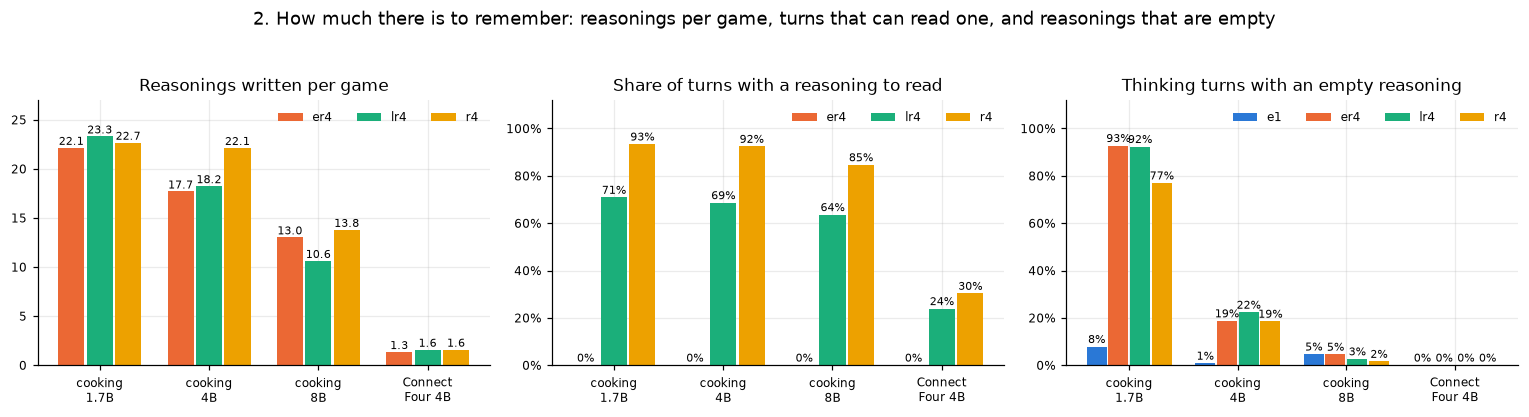

average turns of a player per game:


mode,er4,lr4,r4
Connect Four 4B,8.000,8.400,9.000
cooking 1.7B,91.600,94.800,91.700
cooking 4B,71.700,74.500,89.900
cooking 8B,55.000,45.100,56.400


empty reasonings in cooking, the first five thinking turns of a game against the later ones:


late         first five                   later                  
mode                 e1   er4   lr4    r4    e1   er4   lr4    r4
setting                                                          
cooking 1.7B      0.020 0.670 0.650 0.470 0.080 1.000 1.000 0.850
cooking 4B        0.020 0.030 0.030 0.000 0.010 0.250 0.300 0.240
cooking 8B        0.030 0.030 0.030 0.040 0.050 0.060 0.030 0.000

In [4]:
per_cook = turns.groupby(["model", "mode", "level", "seed"]).agg(turns=("turn", "size"), reasonings=("think", "sum"), visible=("visible", lambda v: (v > 0).mean()))
per_c4 = moves.groupby(["mode", "prompt", "level", "seed", "player"]).agg(turns=("turn", "size"), reasonings=("think", "sum"), visible=("visible", lambda v: (v > 0).mean()))
shape = pd.concat([per_cook.groupby(["model", "mode"]).mean().rename(index=SHORT, level=0).rename(index=lambda m: "cooking " + m, level=0),
                   pd.concat({"Connect Four 4B": per_c4.groupby("mode").mean()})]).loc[lambda t: t.index.get_level_values(1).isin(["er4", "lr4", "r4"])]

logs = [(r, t) for r, t in ma.iter_cooking(RESULTS) if r["prompt"] == "CoT" and r["mode"] in MODES]
empty = pd.DataFrame([dict(setting="cooking " + SHORT[r["model"]], mode=r["mode"], empty=len(x["reasoning"]) < 20, late=k >= 5)
                      for r, t in logs for k, x in enumerate([x for x in t if x["think"]])])
import gate_analysis as ga
mt = ga.move_table(RESULTS, rebuild=False)
mt = mt[mt.judged & mt.think & mt.tokens_think.notna() & mt.player_mode.isin(MODES) & ~mt.prompt.str.contains("+", regex=False)]
empty = pd.concat([empty, pd.DataFrame(dict(setting="Connect Four 4B", mode=mt.player_mode, empty=mt.tokens_think < 30, late=False))])
E = empty.groupby(["setting", "mode"]).empty.mean().unstack()[MODES].loc[settings]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
w = 0.26
for ax, col, title, fmt in [(axes[0], "reasonings", "Reasonings written per game", "{:.1f}"), (axes[1], "visible", "Share of turns with a reasoning to read", "{:.0%}")]:
    for k, m in enumerate(["er4", "lr4", "r4"]):
        v = [shape.loc[(s, m), col] for s in settings]
        ax.bar(np.arange(4) + (k - 1) * w, v, w * 0.92, color=COLOR[m], label=m)
        for i, x in enumerate(v): ax.text(i + (k - 1) * w, x + (0.3 if col == "reasonings" else 0.015), fmt.format(x), ha="center", fontsize=7)
    ax.set_xticks(range(4)); ax.set_xticklabels([s.replace(" ", "\n", 1) for s in settings]); ax.set_title(title); ax.legend(frameon=False, ncol=3, loc="upper right")
    if col == "visible": ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_ylim(0, 1.12)
    else: ax.set_ylim(0, 27)
w = 0.2
for k, m in enumerate(MODES):
    axes[2].bar(np.arange(4) + (k - 1.5) * w, E[m], w * 0.92, color=COLOR[m], label=m)
    for i, x in enumerate(E[m]): axes[2].text(i + (k - 1.5) * w, x + 0.015, f"{x:.0%}", ha="center", fontsize=7)
axes[2].set_xticks(range(4)); axes[2].set_xticklabels([s.replace(" ", "\n", 1) for s in settings]); axes[2].set_ylim(0, 1.12); axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[2].set_title("Thinking turns with an empty reasoning"); axes[2].legend(frameon=False, ncol=4)
fig.suptitle("2. How much there is to remember: reasonings per game, turns that can read one, and reasonings that are empty", y=1.04)
plt.tight_layout(); plt.show()
print("average turns of a player per game:"); display(shape.turns.unstack().round(1))
print("empty reasonings in cooking, the first five thinking turns of a game against the later ones:")
display(empty[empty.setting.str.startswith("cooking")].groupby(["setting", "mode", "late"]).empty.mean().unstack().rename(columns={False: "first five", True: "later"}).round(2).unstack(1))

**Reading 2.** Two facts that come before any question about the content of the reasonings.

- **Connect Four leaves almost nothing to remember.** A player makes about 8 moves in a game, so an every-4 mode writes 1.3-1.6 reasonings
  per game, and only 24-30% of its moves have a reasoning to read. More than half of the moves are played before the first reasoning.
  With one or two reasonings, "the last" and "all" are the same thing: `lr4` and `r4` cannot differ. In cooking a game lasts 45-90 turns,
  with 10-20 reasonings, and 64-71% of `lr4`'s turns have a reasoning in view. Cooking tests a memory; this Connect Four design barely does.
- **In the every-4 modes the small models stop thinking.** With the 1.7B model 77-93% of the thinking turns of `er4`, `lr4` and `r4` are
  empty (8% for `e1`): these modes almost never reason, which is why only `e1` plays. With the 4B it is about 20%, almost all after the
  first five thinking turns (3% early, 25-30% later); with the 8B 2-5%. In Connect Four it never happens: the games end before it can.
  A plausible cause, not tested here: the turns without thinking fill the context with bare answers, and the model continues the pattern.
  For the 4B model this means a fifth of the "reasonings" of the every-4 modes in cooking do not exist, whatever the memory does with them.

## 3. The turns after a reasoning

`since` counts the turns since the player's last reasoning: 0 is the thinking turn, 1-3 the turns played without thinking after it.
On those turns `lr4` and `r4` can read the reasoning and `er4` cannot: the difference between them is what reading it does.
Cooking: share of turns that score a point. Connect Four: share of moves that are blunders, and share that play **the same column the
reasoning played**.

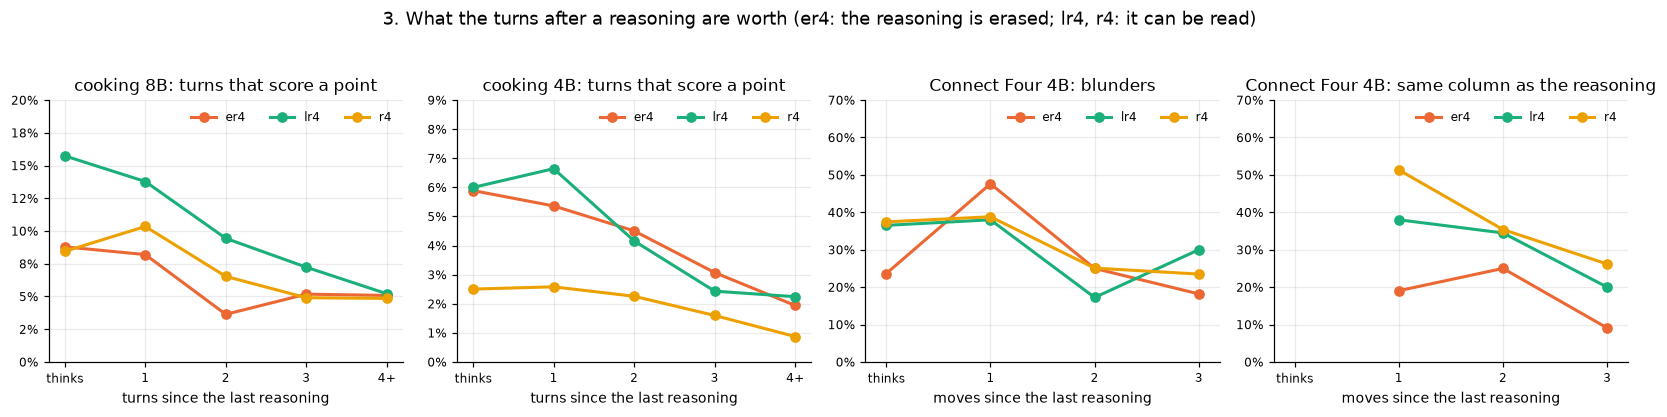

turns 1-3 after a reasoning: reasoning visible (column lr4) against erased (column er4)


,setting,what,lr4,er4,p,test
0,cooking 8B,scores a point,0.164,0.115,0.032,"paired by game, 50 games"
1,cooking 8B,repeats a command of its last 6 turns,0.288,0.355,0.077,"paired by game, 50 games"
2,cooking 8B,command not understood by the game,0.493,0.404,0.007,"paired by game, 50 games"
3,cooking 4B,scores a point,0.077,0.061,0.118,"paired by game, 74 games"
4,cooking 4B,repeats a command of its last 6 turns,0.549,0.580,0.070,"paired by game, 74 games"
5,cooking 4B,command not understood by the game,0.616,0.661,0.088,"paired by game, 74 games"
6,Connect Four 4B,same column as the reasoning (lr4 and r4 toget...,0.416,0.195,0.000,"Fisher, 1016 vs 77 moves"
7,Connect Four 4B,same column as the reasoning (lr4 alone),0.348,0.195,0.037,"Fisher, 89 vs 77 moves"
8,Connect Four 4B,blunder (lr4 and r4 together),0.319,0.364,0.448,"Fisher, 1016 vs 77 moves"


In [5]:
def dist(s): return s.map(lambda x: np.nan if pd.isna(x) else min(int(x), 4))
turns["d"], moves["d"] = dist(turns.since), dist(moves.since)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, model in zip(axes, ["Qwen/Qwen3-8B-FP8", "Qwen/Qwen3-4B"]):
    d = turns[(turns.model == model) & turns.d.notna()]
    for m in ["er4", "lr4", "r4"]:
        r = d[d["mode"] == m].groupby("d").good.mean()
        ax.plot(r.index, r.values, "-o", color=COLOR[m], lw=2, ms=6, label=m)
    ax.set_xticks(range(5)); ax.set_xticklabels(["thinks", "1", "2", "3", "4+"]); ax.set_xlim(-0.2, 4.2); ax.set_ylim(0, 0.2 if "8B" in model else 0.09)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_title(f"cooking {SHORT[model]}: turns that score a point"); ax.set_xlabel("turns since the last reasoning")
d = moves[moves.d.notna()]
for ax, col, title in [(axes[2], "blunder", "Connect Four 4B: blunders"), (axes[3], "repeat", "Connect Four 4B: same column as the reasoning")]:
    for m in ["er4", "lr4", "r4"]:
        x = d[(d["mode"] == m) & (d.d <= 3) & ((d.d > 0) | (col == "blunder"))]
        r = (1 - x.groupby("d").good.mean()) if col == "blunder" else x.groupby("d").repeat.mean()
        ax.plot(r.index, r.values, "-o", color=COLOR[m], lw=2, ms=6, label=m)
    ax.set_xticks(range(4)); ax.set_xticklabels(["thinks", "1", "2", "3"]); ax.set_xlim(-0.2, 3.2); ax.set_ylim(0, 0.7)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.set_title(title); ax.set_xlabel("moves since the last reasoning")
for ax in axes: ax.legend(frameon=False, ncol=3, loc="upper right")
fig.suptitle("3. What the turns after a reasoning are worth (er4: the reasoning is erased; lr4, r4: it can be read)", y=1.04)
plt.tight_layout(); plt.show()

out = []
near = turns[turns.since.between(1, 3)]
for model in ["Qwen/Qwen3-8B-FP8", "Qwen/Qwen3-4B"]:
    for col, what in [("good", "scores a point"), ("repeat", "repeats a command of its last 6 turns"), ("rejected", "command not understood by the game")]:
        g = near[(near.model == model) & near["mode"].isin(["lr4", "er4"])].groupby(["mode", "level", "seed"])[col].apply(lambda s: s.dropna().astype(float).mean()).unstack(0).dropna()
        out.append(dict(setting="cooking " + SHORT[model], what=what, lr4=g.lr4.mean(), er4=g.er4.mean(), p=wilcoxon((g.lr4 - g.er4).astype(float)).pvalue, test=f"paired by game, {len(g)} games"))
nearm = moves[moves.since.between(1, 3)]
vis, er, lr = nearm[nearm["mode"].isin(["lr4", "r4"])], nearm[nearm["mode"] == "er4"], nearm[nearm["mode"] == "lr4"]
out.append(dict(setting="Connect Four 4B", what="same column as the reasoning (lr4 and r4 together)", lr4=vis.repeat.mean(), er4=er.repeat.mean(), p=fisher(vis.repeat, er.repeat), test=f"Fisher, {len(vis)} vs {len(er)} moves"))
out.append(dict(setting="Connect Four 4B", what="same column as the reasoning (lr4 alone)", lr4=lr.repeat.mean(), er4=er.repeat.mean(), p=fisher(lr.repeat, er.repeat), test=f"Fisher, {len(lr)} vs {len(er)} moves"))
out.append(dict(setting="Connect Four 4B", what="blunder (lr4 and r4 together)", lr4=1 - vis.good.mean(), er4=1 - er.good.mean(), p=fisher(~vis.good, ~er.good), test=f"Fisher, {len(vis)} vs {len(er)} moves"))
print("turns 1-3 after a reasoning: reasoning visible (column lr4) against erased (column er4)")
pd.DataFrame(out).round(3)

**Reading 3.**

- **Cooking, 8B: the visible reasoning is used and it pays.** On the three turns after a reasoning `lr4` scores a point on 16% of its turns
  and `er4` on 12% (paired by game, p = 0.03), and it repeats itself less. The effect fades with the distance, as a note that goes out of date.
- **Cooking, 4B: no difference.** The same three turns score the same with the reasoning visible or erased (p = 0.12). Note that even with
  the reasoning erased the turn right after it scores far more than the fourth one: the *action* chosen by the reasoning changes the game
  (an object taken, a command found that the game accepts, and that command stays in the context), and this survives the erasure.
- **Connect Four: the visible reasoning is used, as a column to play again.** After a reasoning that is still in view the next moves go to
  the same column 42% of the time, against 20% when it was erased (p < 0.001; `lr4` alone 35%, p = 0.04). The blunder rate does not move
  (32% against 36%, p = 0.45). The reasoning is not ignored: what it can pass on is one column, and the position that made that
  column right is gone after the opponent's reply.

## 4. What is in a reasoning that could be useful later: 180 reasonings classified

A fixed random sample: 40 reasonings of `lr4` and 20 of `er4` for each of cooking 4B, cooking 8B and Connect Four 4B, each followed by at
least one turn without reasoning (empty reasonings excluded). Every item shows what the game showed, the reasoning, the action, and the
actions that followed with their outcome. The reader does not see the mode. The rubric (`memory_analysis.RUBRIC`) asks:

| Label | Values | Question |
|---|---|---|
| `type` | PLAN, TRACK, REPAIR, EVALUATE, LOST | The one main thing the reasoning does: lay out its next actions; re-establish where it stands on the task; work out why its actions failed and try another way; weigh this turn's options only; reach its action without a usable argument |
| `future_steps` | 0, 1, 2+ | Its own later actions named beyond the one it plays now |
| `fallbacks` | yes / no | It names other things to try if the action fails |
| `durable_facts` | yes / no | It states facts that stay true on the next turns (where things are, which commands work, what is done) |
| `anticipates` | yes / no | It says what the other side will do and what it will answer |
| `state_error` | yes / no / unclear | It misreads the current state, checked against what the game showed |
| `carried` | FOLLOWED, DIVERGED, REPEATED | The next actions pursue what it concluded; do something else; just repeat its action |
| `validity` | VALID, STALE, WRONG | Its conclusion still fitted the next turns; fitted when written but the situation changed; was wrong from the start |

**Who labelled.** The labels are by Claude (six readers, 30 items each, reading the items one by one against the rubric; no keyword rules).
Thirty items were read a second time by another reader who did not see the first labels: the agreement is below. These are a judge's
labels, not human ones: a human check on a subset is still to do (`labels/memory_sample.jsonl` has the items, `labels/memory_labels.csv` the labels).

In [6]:
L = pd.read_csv("labels/memory_labels.csv"); L2 = pd.read_csv("labels/memory_labels_second.csv")
for t in (L, L2): t["state_error"] = t.state_error.astype(str).str.lower()
L["setting"] = np.where(L.game == "cooking", "cooking " + L.model.map(SHORT), "Connect Four 4B")
def kappa(a, b):
    a, b = a.astype(str).values, b.astype(str).values; po = (a == b).mean()
    pe = sum((a == c).mean() * (b == c).mean() for c in set(a) | set(b)); return po, (po - pe) / (1 - pe) if pe < 1 else np.nan
m = L.merge(L2, on="id", suffixes=("", "_2"))
agree = pd.DataFrame({c: kappa(m[c], m[c + "_2"]) for c in ["type", "future_steps", "fallbacks", "durable_facts", "anticipates", "state_error", "carried", "validity"]}, index=["same label", "Cohen's kappa"]).T
print(f"agreement of two readers on {len(m)} items (kappa is undefined for `anticipates`: both said no on every item)"); display(agree.round(2))

agreement of two readers on 30 items (kappa is undefined for `anticipates`: both said no on every item)


,same label,Cohen's kappa
type,0.900,0.850
future_steps,0.930,0.720
fallbacks,0.970,0.900
durable_facts,1.000,1.000
anticipates,1.000,NaN
state_error,0.800,0.700
carried,0.870,0.800
validity,0.870,0.730


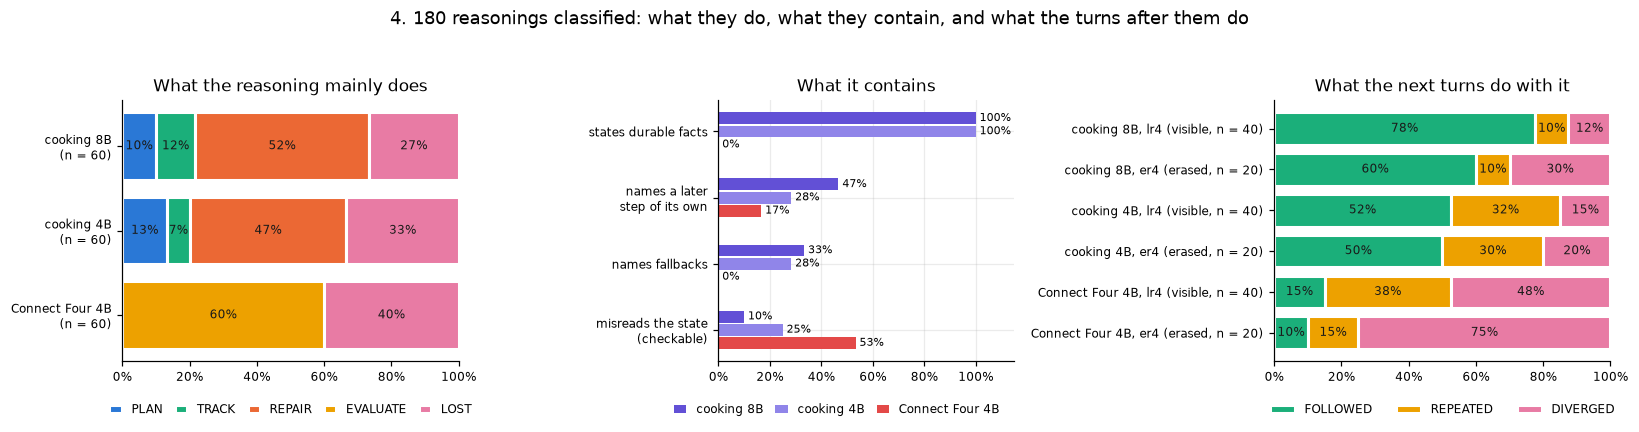

share of each label, per setting (%):


type                        validity              carried                   state_error             
                EVALUATE LOST PLAN REPAIR TRACK    STALE VALID WRONG DIVERGED FOLLOWED REPEATED       false true unclear
setting                                                                                                                 
cooking 8B             0   27   10     52    12        0    40    60       18       72       10          50   10      40
cooking 4B             0   33   13     47     7        0    33    67       17       52       32          33   25      42
Connect Four 4B       60   40    0      0     0       13    28    58       57       13       30          47   53       0

In [7]:
TYPES = ["PLAN", "TRACK", "REPAIR", "EVALUATE", "LOST"]
TCOL = dict(zip(TYPES, ["#2a78d6", "#1baf7a", "#eb6834", "#eda100", "#e87ba4"]))
S3 = ["cooking 8B", "cooking 4B", "Connect Four 4B"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.25, 1.1, 1.25]})
T = pd.crosstab(L.setting, L.type, normalize="index").reindex(index=S3, columns=TYPES).fillna(0)
left = np.zeros(3)
for t in TYPES:
    axes[0].barh(range(3), T[t], left=left, color=TCOL[t], edgecolor="white", linewidth=2, label=t)
    for i, v in enumerate(T[t]):
        if v >= 0.06: axes[0].text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="#1a1a19")
    left += T[t].values
axes[0].set_yticks(range(3)); axes[0].set_yticklabels([f"{s}\n(n = 60)" for s in S3]); axes[0].invert_yaxis(); axes[0].set_xlim(0, 1)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[0].grid(False)
axes[0].legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), columnspacing=1, handlelength=1); axes[0].set_title("What the reasoning mainly does")

P = pd.DataFrame({"states durable facts": L.groupby("setting").durable_facts.mean(), "names a later step of its own": (L.future_steps >= 1).groupby(L.setting).mean(),
                  "names fallbacks": L.groupby("setting").fallbacks.mean(), "misreads the state (checkable)": (L.state_error == "true").groupby(L.setting).mean()}).loc[S3]
SCOL = dict(zip(S3, ["#6250d6", "#9085e9", "#e34948"]))  # the settings, not the modes: other hues; w = 0.26
for k, s in enumerate(S3):
    axes[1].barh(np.arange(4) + (k - 1) * w, P.loc[s], w * 0.9, color=SCOL[s], label=s)
    for i, v in enumerate(P.loc[s]): axes[1].text(v + 0.015, i + (k - 1) * w, f"{v:.0%}", va="center", fontsize=7)
axes[1].set_yticks(range(4)); axes[1].set_yticklabels([c.replace(" (", "\n(").replace("later step", "later\nstep") for c in P.columns]); axes[1].invert_yaxis(); axes[1].set_xlim(0, 1.15)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); axes[1].legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.12), columnspacing=1, handlelength=1); axes[1].set_title("What it contains")

CARR = ["FOLLOWED", "REPEATED", "DIVERGED"]; CCOL = dict(zip(CARR, ["#1baf7a", "#eda100", "#e87ba4"]))
K = pd.crosstab([L.setting, L["mode"]], L.carried, normalize="index").reindex(columns=CARR).fillna(0)
keys = [(s, m) for s in S3 for m in ["lr4", "er4"]]; left = np.zeros(len(keys))
for cc in CARR:
    v = np.array([K.loc[k, cc] for k in keys])
    axes[2].barh(range(len(keys)), v, left=left, color=CCOL[cc], edgecolor="white", linewidth=2, label=cc)
    for i, x in enumerate(v):
        if x >= 0.07: axes[2].text(left[i] + x / 2, i, f"{x:.0%}", ha="center", va="center", fontsize=8, color="#1a1a19")
    left += v
axes[2].set_yticks(range(len(keys))); axes[2].set_yticklabels([f"{s}, {m} ({'visible' if m == 'lr4' else 'erased'}, n = {40 if m == 'lr4' else 20})" for s, m in keys])
axes[2].invert_yaxis(); axes[2].set_xlim(0, 1); axes[2].grid(False); axes[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[2].legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12)); axes[2].set_title("What the next turns do with it")
fig.suptitle("4. 180 reasonings classified: what they do, what they contain, and what the turns after them do", y=1.04)
plt.tight_layout(); plt.show()
print("share of each label, per setting (%):")
display((pd.concat({c: pd.crosstab(L.setting, L[c], normalize="index") for c in ["type", "validity", "carried", "state_error"]}, axis=1).loc[S3] * 100).round(0).astype(int))

In [8]:
L["after"] = L.after_good / L.after_n; L["any_good"] = L.after_good > 0
print("what followed, by the validity of the reasoning (cooking: share of the next turns that score a point, and reasonings followed by at least one point; Connect Four: share of the next moves that are not blunders)")
display(L.groupby(["setting", "validity"]).agg(reasonings=("id", "size"), next_turns_good=("after", "mean"), at_least_one_good=("any_good", "mean")).loc[S3].round(2))
t = []
for s in S3:
    d = L[L.setting == s]
    for label, col, val in [("next turns FOLLOWED the reasoning", "carried", "FOLLOWED"), ("next turns REPEATED its action", "carried", "REPEATED")]:
        a, b = d[d["mode"] == "lr4"][col] == val, d[d["mode"] == "er4"][col] == val
        t.append(dict(setting=s, what=label, visible_lr4=a.mean(), erased_er4=b.mean(), p=fisher(a, b)))
    if s.startswith("cooking"):
        a, b = d[d.validity == "VALID"].any_good, d[d.validity == "WRONG"].any_good
        t.append(dict(setting=s, what="a point follows: VALID reasoning (visible column) vs WRONG (erased column)", visible_lr4=a.mean(), erased_er4=b.mean(), p=fisher(a, b)))
pd.DataFrame(t).round(3)

what followed, by the validity of the reasoning (cooking: share of the next turns that score a point, and reasonings followed by at least one point; Connect Four: share of the next moves that are not blunders)


reasonings  next_turns_good  at_least_one_good
setting         validity                                                
cooking 8B      VALID             24            0.290              0.620
                WRONG             36            0.020              0.060
cooking 4B      VALID             20            0.110              0.300
                WRONG             40            0.010              0.020
Connect Four 4B STALE              8            0.690              0.880
                VALID             17            0.770              0.880
                WRONG             35            0.670              0.860

,setting,what,visible_lr4,erased_er4,p
0,cooking 8B,next turns FOLLOWED the reasoning,0.775,0.600,0.225
1,cooking 8B,next turns REPEATED its action,0.100,0.100,1.000
2,cooking 8B,a point follows: VALID reasoning (visible colu...,0.625,0.056,0.000
3,cooking 4B,next turns FOLLOWED the reasoning,0.525,0.500,1.000
4,cooking 4B,next turns REPEATED its action,0.325,0.300,1.000
5,cooking 4B,a point follows: VALID reasoning (visible colu...,0.300,0.025,0.004
6,Connect Four 4B,next turns FOLLOWED the reasoning,0.150,0.100,0.707
7,Connect Four 4B,next turns REPEATED its action,0.375,0.150,0.084


**Reading 4.** The two games ask the reasoning for different things, and what they get is of a different kind.

- **In cooking a reasoning is a note about a task; in Connect Four it is a look at one position.** Every cooking reasoning in the sample
  states facts that stay true on the next turns (what the recipe asks, what is done, where things are, which commands the game refused);
  half are REPAIR (why did the last commands fail, what else to try), a tenth are PLAN, a third name fallbacks, and 30-50% name a later
  step of their own. In Connect Four none states a durable fact, none names a fallback or a second later step, one in sixty anticipates
  a concrete reply: 60% are EVALUATE (this turn's options) and 40% LOST. There is nothing in them addressed to a later turn.
- **Connect Four reasonings misread what they look at.** In 53% a statement about the board is false against the board shown (a disc in
  the wrong column, a column taken as full once its bottom cell is occupied). In cooking it is 10% (8B) and 25% (4B) of the reasonings,
  with 40% not checkable from the item.
- **Most reasonings are wrong in both games, and only in cooking does it matter for what follows.** About 60% of the conclusions are WRONG
  from the start in all three settings. In cooking a VALID reasoning is followed by a point 62% of the time with the 8B and 30% with the
  4B, a WRONG one 6% and 2%: when the note is right, the turns without thinking cash it in. In Connect Four what follows is the same
  after a VALID, a STALE and a WRONG reasoning.
- **STALE exists only in Connect Four** (13%): a conclusion that was right and that the opponent's reply made obsolete. In cooking nothing
  changes unless the player changes it.
- **What the next turns do.** In cooking with the 8B they follow the reasoning in 78% of the cases when it is visible and 60% when erased;
  with the 4B 52% and 50%. In Connect Four they follow it in 15% and 10%, and repeat its column in 38% against 15%. These differences
  go the way of part 3, but on 40 and 20 items none is significant on its own (p between 0.08 and 1): part 3 is the test, this is the reading.

## Verdict

**Why `lr4` works in cooking and not in Connect Four.** Four reasons, in order of how much the data supports them.

1. **Connect Four needs a fresh look at every move; cooking does not.** Thinking every fourth turn loses 44% of the score in Connect Four
   and 16-24% in cooking. A cooking reasoning chooses an action that changes the game for good (and the accepted command stays in the
   context), so the turns after it score even when the reasoning is erased. In Connect Four every move answers a new position, and a move
   without thinking blunders 40% of the time whatever came before.
2. **This Connect Four design gives the memory almost nothing to do.** One or two reasonings per game, a reasoning in view on a quarter of the
   moves, "last" and "all" the same thing. The memory modes differ on too few moves for a difference to show. This is a limit of the
   experiment, not yet a fact about the game.
3. **What a reasoning contains is reusable in cooking and not in Connect Four.** Cooking reasonings are notes on a task that does not move:
   what is done, what is next, what failed and what else to try. Connect Four reasonings evaluate one position, half of the time misreading
   it, and say nothing about later turns. The one thing the next move can take from them is the column, and it does: the same column is
   replayed twice as often when the reasoning is visible, with no fewer blunders.
4. **The benefit of the last reasoning in cooking belongs to the 8B model.** There the turns after a visible reasoning score more
   (16% against 12%, p = 0.03) and the game score is 0.17 higher (p = 0.008). With the 4B, the model of Connect Four, the last reasoning
   changes nothing in cooking either; `lr4` stands out there because `r4` collapses. With the 1.7B the every-4 modes do not reason at all.

**What is not settled.** The games and the models are confounded: the memory effect is an 8B result in cooking, and Connect Four was only
played with the 4B. The classification is by a judge, with good agreement between two readings (kappa 0.70-0.90) but no human check yet.

**What would settle it.**
- Connect Four with the 8B model, `e1` / `er4` / `lr4` / `r4`: does the model that uses its notes in cooking use them here?
- A longer two-player game, or Connect Four on a larger board, so that a game has ten reasonings and not one or two.
- A prompt that asks the Connect Four reasoning to end with a note for the next moves (the threats to watch, the plan): does a reasoning
  written to be reused get reused? Section 4 says today's reasonings contain nothing to reuse.
- The empty reasonings: forbid them (a minimum of thinking tokens) and replay the every-4 modes in cooking with the 1.7B and 4B models.